# Energy-Efficient Approximate Computing for ML
Approximate 8-bit multipliers (EvoApproxLib + own designs) emulated inside an int8 CNN on CIFAR-10.

**Runtime:** Runtime > Change runtime type > T4 GPU. Run the cells top to bottom.
Approach: every 8x8 multiplier is tabulated into a 256 x 256 lookup table (LUT) and used for every multiplication in the conv/linear layers. Accumulation is exact int32.

## 0. Setup

In [ ]:
import os, sys, importlib
import torch
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Switch the runtime to GPU (T4)"
DEVICE = "cuda"

# Optional: keep results on Google Drive so a disconnect does not lose them
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/approx_project"
except Exception as e:
    print("Drive not mounted, using local disk:", e)
    WORK = "/content/approx_project"
os.makedirs(WORK, exist_ok=True)
print("WORK =", WORK)

torch 2.11.0+cu130 | cuda: True
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WORK = /content/drive/MyDrive/approx_project


In [ ]:
!git clone -q https://github.com/ehw-fit/evoapproxlib /content/evoapproxlib 2>/dev/null || echo "repo already cloned"
!ls /content/evoapproxlib/multiplers/8x8_signed

repo already cloned
pareto_pwr_ep  pareto_pwr_mae  pareto_pwr_mre  pareto_pwr_mse  pareto_pwr_wce


## 1. Library code
This cell writes `approx_ml.py` (LUT generation, own multipliers, quantized approximate layers, energy model, sweep, plots).
Commit this file to your GitHub repo as part of the deliverable.

In [ ]:
%%writefile approx_ml.py
"""
approx_ml.py
Approximate-multiplier emulation for CNN inference (EvoApproxLib, 8x8 signed).

Idea: an 8-bit multiplier has only 256 x 256 input pairs, so we precompute its
full truth table (LUT) and use it in place of exact multiplication inside the
conv/linear layers of an int8-quantized CNN. Accumulation is exact int32.

Sections
  1. LUT generation (EvoApproxLib C models + our own designs)
  2. Error metrics and energy model
  3. CNN, BN folding, quantized layers with LUT multiplication
  4. Data, training, evaluation
  5. Sweep, per-layer sensitivity, plots
"""
import ctypes
import glob
import os
import re
import subprocess
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

VALS = np.arange(-128, 128, dtype=np.int32)          # int8 operand range
EXACT_LUT = (VALS[:, None] * VALS[None, :]).astype(np.int32)   # [a+128, b+128]


# ---------------------------------------------------------------------------
# 1. LUT generation
# ---------------------------------------------------------------------------
def parse_header(c_path):
    """Read the '// MAE = ...' style comments at the top of an EvoApproxLib C file."""
    params = {}
    with open(c_path) as f:
        for line in f:
            if not line.startswith("//"):
                continue
            m = re.match(r"//\s*([A-Za-z0-9_]+)(%)?\s*=\s*([0-9.eE+\-]+)", line)
            if m:
                key = m.group(1) + ("_PCT" if m.group(2) else "")
                params[key] = float(m.group(3))
    return params


def lut_from_c(c_path, build_dir="build_so"):
    """Compile one EvoApproxLib 8x8 signed C model and tabulate all 65536 products."""
    os.makedirs(build_dir, exist_ok=True)
    name = os.path.splitext(os.path.basename(c_path))[0]
    so = os.path.abspath(os.path.join(build_dir, name + ".so"))
    subprocess.run(["gcc", "-O2", "-shared", "-fPIC", "-o", so, c_path], check=True)
    fn = getattr(ctypes.CDLL(so), name)
    fn.argtypes = [ctypes.c_int8, ctypes.c_int8]
    fn.restype = ctypes.c_int16
    lut = np.empty((256, 256), dtype=np.int32)
    for i, a in enumerate(VALS.tolist()):
        for j, b in enumerate(VALS.tolist()):
            lut[i, j] = fn(a, b)
    return name, lut


def error_metrics(lut):
    """Error metrics computed directly from a LUT (same for library and own designs)."""
    err = np.abs(lut.astype(np.int64) - EXACT_LUT)
    rel = err / np.maximum(np.abs(EXACT_LUT), 1)
    return {
        "MAE": float(err.mean()),
        "MAE_pct": float(err.mean() / 2 ** 16 * 100),
        "WCE": float(err.max()),
        "WCE_pct": float(err.max() / 2 ** 16 * 100),
        "EP_pct": float((err != 0).mean() * 100),
        "MRE_pct": float(rel.mean() * 100),
    }


def load_evoapprox_multipliers(repo_dir, group="8x8_signed", build_dir="build_so"):
    """
    Returns {name: entry}. Every unique circuit found in the Pareto subsets of the
    chosen group is compiled and tabulated. Entry keys: lut, family, lib_params.
    """
    paths = sorted(glob.glob(os.path.join(repo_dir, "multiplers", group, "*", "mul*.c")))
    unique = {}
    for p in paths:
        unique[os.path.splitext(os.path.basename(p))[0]] = p
    out = {}
    for name, p in unique.items():
        _, lut = lut_from_c(p, build_dir)
        out[name] = {"lut": lut, "family": "EvoApprox", "lib_params": parse_header(p)}
    return out


def _sign_mag(v):
    return np.sign(v), np.abs(v)


def lut_drop_partial_products(k):
    """Own design A: sign-magnitude array multiplier with all partial products
    a_i*b_j where i+j < k removed (column truncation)."""
    s_a, m_a = _sign_mag(VALS[:, None])
    s_b, m_b = _sign_mag(VALS[None, :])
    prod = np.zeros((256, 256), dtype=np.int64)
    for i in range(8):
        for j in range(8):
            if i + j >= k:
                prod += (((m_a >> i) & 1) & ((m_b >> j) & 1)).astype(np.int64) << (i + j)
    lut = (s_a * s_b * prod).astype(np.int32)
    kept = sum(1 for i in range(8) for j in range(8) if i + j >= k) / 64.0
    return lut, kept


def lut_truncate_operands(k):
    """Own design B: zero the k least significant magnitude bits of both operands,
    then multiply exactly (a smaller multiplier is enough in hardware)."""
    s_a, m_a = _sign_mag(VALS[:, None])
    s_b, m_b = _sign_mag(VALS[None, :])
    ta = (m_a >> k) << k
    tb = (m_b >> k) << k
    lut = (s_a * s_b * ta * tb).astype(np.int32)
    kept = ((8 - k) ** 2) / 64.0
    return lut, kept


def build_own_multipliers(drop_ks=(2, 4, 6, 8), trunc_ks=(1, 2, 3, 4)):
    out = {}
    for k in drop_ks:
        lut, kept = lut_drop_partial_products(k)
        out[f"own_dropPP_k{k}"] = {"lut": lut, "family": "Own", "proxy_energy": kept}
    for k in trunc_ks:
        lut, kept = lut_truncate_operands(k)
        out[f"own_truncOp_k{k}"] = {"lut": lut, "family": "Own", "proxy_energy": kept}
    return out


# ---------------------------------------------------------------------------
# 2. Energy model (multiplier energy only)
# ---------------------------------------------------------------------------
def attach_energy(registry, exact_name="mul8s_1KV8", macs_per_image=None):
    """
    Library designs: energy per multiplication = PDK45_PWR [mW] * PDK45_DELAY [ns] = pJ.
    Own designs: no synthesis data, so we use a crude proxy: fraction of partial-product
    AND gates kept, times the exact multiplier's energy. Rows are tagged accordingly.
    """
    ex = registry[exact_name]["lib_params"]
    e_exact = ex["PDK45_PWR"] * ex["PDK45_DELAY"]
    p_exact = ex["PDK45_PWR"]
    for name, e in registry.items():
        if e["family"] == "EvoApprox":
            p = e["lib_params"]
            e["pdp_pj"] = p["PDK45_PWR"] * p["PDK45_DELAY"]
            e["rel_power"] = p["PDK45_PWR"] / p_exact
            e["energy_source"] = "PDK45 synthesis (library)"
        else:
            e["pdp_pj"] = e_exact * e["proxy_energy"]
            e["rel_power"] = e["proxy_energy"]
            e["energy_source"] = "partial-product proxy"
        e["rel_energy"] = e["pdp_pj"] / e_exact
        if macs_per_image is not None:
            e["mult_energy_nj_per_image"] = e["pdp_pj"] * macs_per_image / 1000.0
    return registry


# ---------------------------------------------------------------------------
# 3. Model, BN folding, quantized layers
# ---------------------------------------------------------------------------
def make_cnn(bn=True, num_classes=10):
    def block(cin, cout):
        layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=not bn)]
        if bn:
            layers.append(nn.BatchNorm2d(cout))
        layers += [nn.ReLU(), nn.MaxPool2d(2)]
        return layers

    fc1 = [nn.Linear(128 * 4 * 4, 256)]
    if bn:
        fc1.append(nn.BatchNorm1d(256))
    return nn.Sequential(
        *block(3, 32), *block(32, 64), *block(64, 128),
        nn.Flatten(), *fc1, nn.ReLU(), nn.Linear(256, num_classes),
    )


def fold_bn(model):
    """Return a BN-free copy of a Sequential CNN (BN folded into conv/linear)."""
    folded = make_cnn(bn=False)
    dst = list(folded)
    mods = list(model)
    # walk the original model, pairing each conv/linear with a following BN if present
    di = 0
    i = 0
    while i < len(mods):
        m = mods[i]
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            w = m.weight.data.clone()
            b = m.bias.data.clone() if m.bias is not None else torch.zeros(w.shape[0], device=w.device)
            if i + 1 < len(mods) and isinstance(mods[i + 1], (nn.BatchNorm2d, nn.BatchNorm1d)):
                bnm = mods[i + 1]
                s = bnm.weight.data / torch.sqrt(bnm.running_var + bnm.eps)
                w = w * s.view(-1, *([1] * (w.dim() - 1)))
                b = (b - bnm.running_mean) * s + bnm.bias.data
                i += 1
            while not isinstance(dst[di], (nn.Conv2d, nn.Linear)):
                di += 1
            dst[di].weight.data.copy_(w)
            dst[di].bias.data.copy_(b)
            di += 1
        i += 1
    return folded.to(next(model.parameters()).device)


def count_macs(float_model, input_shape=(1, 3, 32, 32)):
    """Multiply-accumulates per image for conv/linear layers."""
    total = [0]
    hooks = []

    def hook(mod, inp, out):
        per_out = mod.weight[0].numel()
        total[0] += int(out.numel() // out.shape[0] * per_out)

    for m in float_model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            hooks.append(m.register_forward_hook(hook))
    dev = next(float_model.parameters()).device
    was_training = float_model.training
    float_model.eval()
    with torch.no_grad():
        float_model(torch.zeros(input_shape, device=dev))
    for h in hooks:
        h.remove()
    float_model.train(was_training)
    return total[0]


def lut_matmul(xq, wq, lut_flat, budget=1 << 24):
    """
    acc[m, o] = sum_k LUT[xq[m,k], wq[o,k]]   (exact int32 accumulation)
    xq: (M,K) int64 in [-128,127] (activations, first multiplier operand)
    wq: (O,K) int64 in [-128,127] (weights, second multiplier operand)
    """
    M, K = xq.shape
    O = wq.shape[0]
    xi = (xq + 128) * 256
    wi = wq + 128
    out = torch.empty(M, O, dtype=torch.int32, device=xq.device)
    rows = max(1, budget // (O * K))
    for r in range(0, M, rows):
        idx = xi[r:r + rows, None, :] + wi[None, :, :]
        out[r:r + rows] = lut_flat[idx].sum(-1, dtype=torch.int32)
    return out


class QLayer(nn.Module):
    """
    Wraps a Conv2d/Linear. Modes:
      'float': ordinary float layer
      'calib': float layer, also records activation range
      'int'  : exact int8 x int8 -> int32 (float64 matmul, bit exact)
      'lut'  : every product comes from the LUT (approximate multiplier)
    Zero padding in convs also goes through the multiplier, as in real hardware
    that does not skip zero operands.
    """

    def __init__(self, layer):
        super().__init__()
        self.layer = layer
        self.is_conv = isinstance(layer, nn.Conv2d)
        w = layer.weight.data.flatten(1)
        self.register_buffer("w_scale", (w.abs().amax(1).clamp_min(1e-8) / 127.0))
        self.register_buffer("wq", torch.round(w / self.w_scale[:, None]).clamp(-128, 127).long())
        self.x_scale = None
        self.mode = "float"
        self.lut_flat = None
        self._calib = []

    def quant_x(self, x):
        return torch.round(x / self.x_scale).clamp(-128, 127)

    def forward(self, x):
        if self.mode in ("float", "calib"):
            if self.mode == "calib":
                flat = x.detach().abs().flatten()
                if flat.numel() > 1_000_000:
                    flat = flat[torch.randint(0, flat.numel(), (1_000_000,), device=flat.device)]
                self._calib.append(torch.quantile(flat.float(), 0.9999).item())
            return self.layer(x)

        xq = self.quant_x(x)
        if self.is_conv:
            c = self.layer
            N, _, H, W = x.shape
            cols = F.unfold(xq, c.kernel_size, c.dilation, c.padding, c.stride)  # (N,K,L)
            L = cols.shape[-1]
            cols = cols.transpose(1, 2).reshape(N * L, -1)
            Ho = (H + 2 * c.padding[0] - c.dilation[0] * (c.kernel_size[0] - 1) - 1) // c.stride[0] + 1
            Wo = (W + 2 * c.padding[1] - c.dilation[1] * (c.kernel_size[1] - 1) - 1) // c.stride[1] + 1
        else:
            cols = xq.reshape(-1, xq.shape[-1])
            N = cols.shape[0]

        if self.mode == "int":
            acc = (cols.double() @ self.wq.double().T).round().to(torch.int32)
        else:  # 'lut'
            acc = lut_matmul(cols.long(), self.wq, self.lut_flat)

        out = acc.float() * (self.x_scale * self.w_scale)[None, :] + self.layer.bias[None, :]
        if self.is_conv:
            out = out.view(N, Ho * Wo, -1).transpose(1, 2).reshape(N, -1, Ho, Wo)
        return out


def quantize_model(folded):
    """Deep-copy a BN-free CNN and wrap every conv/linear in a QLayer."""
    import copy
    q = copy.deepcopy(folded)
    for i, m in enumerate(q):
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            q[i] = QLayer(m)
    return q


def qlayers(model):
    return [m for m in model if isinstance(m, QLayer)]


def use_float(model):
    for l in qlayers(model):
        l.mode = "float"


@torch.no_grad()
def calibrate(model, x_calib, batch=256):
    """Set per-layer activation scales from a calibration set (99.99th percentile)."""
    model.eval()
    for l in qlayers(model):
        l.mode, l._calib = "calib", []
    for i in range(0, len(x_calib), batch):
        model(x_calib[i:i + batch])
    for l in qlayers(model):
        l.x_scale = max(float(np.mean(l._calib)), 1e-8) / 127.0
        l.mode = "float"


def use_int(model):
    for l in qlayers(model):
        l.mode = "int"


def use_lut(model, lut, layers=None, swap=False):
    """Approximate multiplier in `layers` (indices into qlayers, default all); the rest stay exact.
    swap=True exchanges the two multiplier operands (matters: approximate multipliers
    are generally not commutative)."""
    dev = qlayers(model)[0].wq.device
    t = torch.from_numpy(lut.T.copy() if swap else lut).to(dev).to(torch.int32).flatten()
    for i, l in enumerate(qlayers(model)):
        if layers is None or i in layers:
            l.mode, l.lut_flat = "lut", t
        else:
            l.mode = "int"


# ---------------------------------------------------------------------------
# 4. Data, training, evaluation
# ---------------------------------------------------------------------------
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)


def load_cifar10(root="./data", device="cuda"):
    from torchvision import datasets
    tr = datasets.CIFAR10(root, train=True, download=True)
    te = datasets.CIFAR10(root, train=False, download=True)
    mean = torch.tensor(CIFAR_MEAN).view(1, 3, 1, 1)
    std = torch.tensor(CIFAR_STD).view(1, 3, 1, 1)

    def prep(ds):
        x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).float() / 255.0
        return ((x - mean) / std).to(device), torch.tensor(ds.targets).to(device)

    return (*prep(tr), *prep(te))


def train_model(model, xtr, ytr, xte, yte, epochs=20, batch=128, lr=0.1, wd=5e-4, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
    steps = epochs * ((len(xtr) + batch - 1) // batch)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(xtr), device=xtr.device)
        t0 = time.time()
        for i in range(0, len(xtr), batch):
            idx = perm[i:i + batch]
            x, y = xtr[idx], ytr[idx]
            flip = torch.rand(len(x), device=x.device) < 0.5
            x = torch.where(flip[:, None, None, None], x.flip(3), x)
            dx, dy = np.random.randint(-3, 4, 2)
            x = torch.roll(x, shifts=(int(dy), int(dx)), dims=(2, 3))
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
        acc = evaluate(model, xte, yte)
        print(f"epoch {ep + 1:2d}/{epochs}  loss {loss.item():.3f}  test acc {acc:.4f}  ({time.time() - t0:.1f}s)")
    return model


@torch.no_grad()
def evaluate(model, x, y, n=None, batch=100):
    model.eval()
    n = len(x) if n is None else min(n, len(x))
    correct = 0
    for i in range(0, n, batch):
        correct += (model(x[i:i + batch][: n - i]).argmax(1) == y[i:i + batch][: n - i]).sum().item()
    return correct / n


@torch.no_grad()
def check_exact_lut(model, x, atol=1e-5):
    """Sanity check: the exact multiplier's LUT must reproduce plain int8 arithmetic."""
    use_int(model)
    ref = model(x)
    use_lut(model, EXACT_LUT)
    got = model(x)
    diff = (ref - got).abs().max().item()
    print(f"max |logit difference| exact-LUT vs int8 reference: {diff:.3e}")
    assert diff < atol, "Exact LUT does not match int8 reference. Fix this before any experiment."
    return diff


# ---------------------------------------------------------------------------
# 5. Sweep, per-layer sensitivity, plots
# ---------------------------------------------------------------------------
def run_sweep(model, registry, x, y, n_eval, csv_path, swap=False, baseline_acc=None, tag=""):
    """Evaluate every multiplier; resumable (rows already in csv_path are skipped)."""
    done = set()
    rows = []
    if os.path.exists(csv_path):
        old = pd.read_csv(csv_path)
        rows = old.to_dict("records")
        done = set(zip(old["name"], old["swap"], old["tag"].fillna("")))
    for name, e in registry.items():
        if (name, swap, tag) in done:
            continue
        t0 = time.time()
        use_lut(model, e["lut"], swap=swap)
        acc = evaluate(model, x, y, n=n_eval)
        m = error_metrics(e["lut"])
        row = {"name": name, "family": e["family"], "swap": swap, "tag": tag, "n_eval": n_eval,
               "acc": acc, "acc_drop": (baseline_acc - acc) if baseline_acc is not None else np.nan,
               "rel_energy": e["rel_energy"], "energy_saving_pct": (1 - e["rel_energy"]) * 100,
               "rel_power": e["rel_power"], "pdp_pj": e["pdp_pj"],
               "mult_energy_nj_per_image": e.get("mult_energy_nj_per_image", np.nan),
               "energy_source": e["energy_source"], "emul_seconds": time.time() - t0, **m}
        rows.append(row)
        pd.DataFrame(rows).to_csv(csv_path, index=False)
        print(f"{name:20s} acc {acc:.4f}  energy {e['rel_energy']:.3f}x  MAE% {m['MAE_pct']:.4f}  ({row['emul_seconds']:.0f}s)")
    return pd.DataFrame(rows)


def layer_sensitivity(model, lut, x, y, n_eval):
    """Approximate one layer at a time (others exact). Returns accuracy per layer."""
    res = []
    for i in range(len(qlayers(model))):
        use_lut(model, lut, layers=[i])
        res.append(evaluate(model, x, y, n=n_eval))
    return res


def pareto_front(df, x="energy_saving_pct", y="acc"):
    """Non-dominated rows: maximize both energy saving and accuracy."""
    d = df.sort_values([x, y], ascending=[False, False])
    best, keep = -1.0, []
    for idx, r in d.iterrows():
        if r[y] > best:
            keep.append(idx)
            best = r[y]
    return df.loc[keep].sort_values(x)


def make_plots(df, baseline_acc, out_dir="results"):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    os.makedirs(out_dir, exist_ok=True)
    d = df[(df["swap"] == False) & (df["tag"].fillna("") == "")]

    fig, ax = plt.subplots(figsize=(7, 4.5))
    for fam, mk in (("EvoApprox", "o"), ("Own", "s")):
        s = d[d["family"] == fam]
        ax.scatter(s["energy_saving_pct"], s["acc"] * 100, marker=mk, label=fam)
        for _, r in s.iterrows():
            ax.annotate(r["name"].replace("mul8s_", "").replace("own_", ""), (r["energy_saving_pct"], r["acc"] * 100),
                        fontsize=6, xytext=(3, 3), textcoords="offset points")
    pf = pareto_front(d)
    ax.plot(pf["energy_saving_pct"], pf["acc"] * 100, "k--", lw=1, label="Pareto front")
    ax.axhline(baseline_acc * 100, color="gray", lw=0.8, ls=":", label="exact int8")
    ax.set_xlabel("Estimated multiplier energy saving (%)")
    ax.set_ylabel("Top-1 accuracy (%)")
    ax.set_title("Accuracy vs estimated multiplier energy saving")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "pareto_acc_vs_energy.png"), dpi=200)

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.scatter(d["MAE_pct"].clip(lower=1e-4), d["acc"] * 100, c=d["family"].map({"EvoApprox": "C0", "Own": "C1"}))
    ax.set_xscale("log")
    ax.set_xlabel("Multiplier MAE (% of output range, log scale)")
    ax.set_ylabel("Top-1 accuracy (%)")
    ax.set_title("Accuracy vs multiplier error")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, "acc_vs_mae.png"), dpi=200)
    plt.close("all")

Overwriting approx_ml.py


In [ ]:
import approx_ml as am
importlib.reload(am)
import numpy as np, pandas as pd

## 2. Multiplier LUTs and error metrics
Compiles all 8x8 signed EvoApproxLib circuits found in the repo (13 unique ones) and adds two own designs:
* `own_dropPP_k`: array multiplier with partial products in the k least significant columns removed
* `own_truncOp_k`: zero the k least significant bits of both operands, then multiply

`mul8s_1KV8` is the exact multiplier and serves as the energy baseline.

In [ ]:
registry = am.load_evoapprox_multipliers("/content/evoapproxlib", "8x8_signed", build_dir="/content/build_so")
registry.update(am.build_own_multipliers(drop_ks=(2, 4, 6, 8), trunc_ks=(1, 2, 3, 4)))
print(len(registry), "multipliers")

# Validation: our MAE computed from the LUT must match the MAE printed in the library's C file header
for n, e in registry.items():
    if e["family"] == "EvoApprox":
        mine, lib = am.error_metrics(e["lut"])["MAE"], e["lib_params"]["MAE"]
        assert abs(mine - lib) <= max(1.0, 0.01 * lib), (n, mine, lib)
assert np.array_equal(registry["mul8s_1KV8"]["lut"], am.EXACT_LUT), "mul8s_1KV8 should be exact"
print("LUT generation validated against library metrics")

21 multipliers
LUT generation validated against library metrics


## 3. Train the baseline CNN (FP32)
Small CNN (3 conv blocks + 2 FC, about 10.8 M MACs per image) with BatchNorm. Takes a few minutes on a T4.

In [ ]:
xtr, ytr, xte, yte = am.load_cifar10("/content/data", DEVICE)
ckpt = os.path.join(WORK, "cnn_bn.pt")
model = am.make_cnn(bn=True).to(DEVICE)
if os.path.exists(ckpt):
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    print("loaded", ckpt)
else:
    am.train_model(model, xtr, ytr, xte, yte, epochs=20)
    torch.save(model.state_dict(), ckpt)
print("FP32 test accuracy:", am.evaluate(model, xte, yte))

loaded /content/drive/MyDrive/approx_project/cnn_bn.pt
FP32 test accuracy: 0.8703


## 4. Fold BatchNorm, quantize to int8, calibrate, and verify the emulation
The check at the end is the most important one: **the exact multiplier's LUT must give identical results to plain int8 arithmetic.** Do not run experiments if it fails.

In [ ]:
folded = am.fold_bn(model)
folded.eval()
macs = am.count_macs(folded)
print(f"MACs per image: {macs:,}")
print("folded FP32 accuracy:", am.evaluate(folded, xte, yte))

qmodel = am.quantize_model(folded)
am.calibrate(qmodel, xtr[:2000])
am.use_float(qmodel)
print("QLayer float-path accuracy:", am.evaluate(qmodel, xte, yte))

am.check_exact_lut(qmodel, xte[:16])

N_EVAL = 10000          # use 10000 (full test set) for final numbers
am.use_int(qmodel)
baseline_acc = am.evaluate(qmodel, xte, yte, n=N_EVAL)
print(f"exact int8 accuracy on first {N_EVAL} test images: {baseline_acc:.4f}")

registry = am.attach_energy(registry, exact_name="mul8s_1KV8", macs_per_image=macs)

MACs per image: 10,848,768
folded FP32 accuracy: 0.8703
QLayer float-path accuracy: 0.8703
max |logit difference| exact-LUT vs int8 reference: 0.000e+00
exact int8 accuracy on first 10000 test images: 0.8696


## 5. Main sweep: accuracy vs multiplier
Results are appended to a CSV in `WORK` after every multiplier, so the cell can be re-run after a disconnect and it resumes.
If you change `N_EVAL`, delete the CSV first.

In [ ]:
CSV = os.path.join(WORK, "sweep_results.csv")
df = am.run_sweep(qmodel, registry, xte, yte, N_EVAL, CSV, swap=False, baseline_acc=baseline_acc)
df.sort_values("energy_saving_pct")[["name", "family", "acc", "acc_drop", "energy_saving_pct",
                                      "MAE_pct", "WCE_pct", "EP_pct", "MRE_pct"]].round(4)

,name,family,acc,acc_drop,energy_saving_pct,MAE_pct,WCE_pct,EP_pct,MRE_pct
3,mul8s_1KV8,EvoApprox,0.8700,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
24,mul8s_1KV8,EvoApprox,0.8700,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
27,mul8s_1KVA,EvoApprox,0.8699,0.0001,0.7059,0.0019,0.0076,50.0000,0.2730
6,mul8s_1KVA,EvoApprox,0.8699,0.0001,0.7059,0.0019,0.0076,50.0000,0.2730
7,mul8s_1KVB,EvoApprox,0.8650,0.0050,4.1812,0.0065,0.0259,68.7500,0.8954
28,mul8s_1KVB,EvoApprox,0.8650,0.0050,4.1812,0.0065,0.0259,68.7500,0.8954
13,own_dropPP_k2,Own,0.8692,0.0008,4.6875,0.0019,0.0076,50.0000,0.2438
12,mul8s_1KX2,EvoApprox,0.8428,0.0272,6.1351,0.0187,0.0748,81.2500,2.5099
33,mul8s_1KX2,EvoApprox,0.8428,0.0272,6.1351,0.0187,0.0748,81.2500,2.5099
14,own_dropPP_k4,Own,0.8700,0.0000,15.6250,0.0187,0.0748,81.2500,1.7038


## 6. Plots (Pareto front and error correlation)

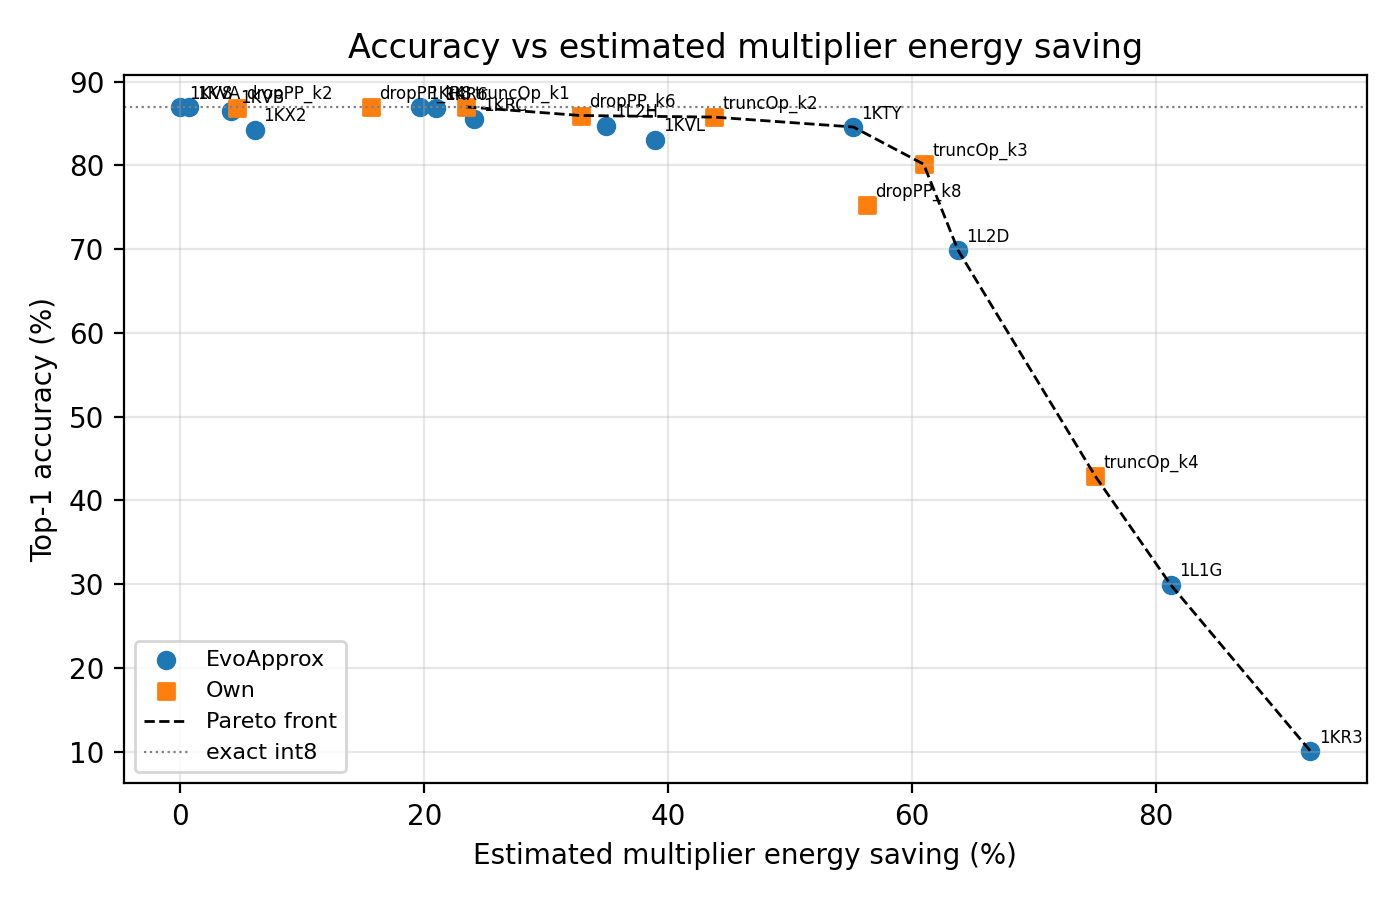

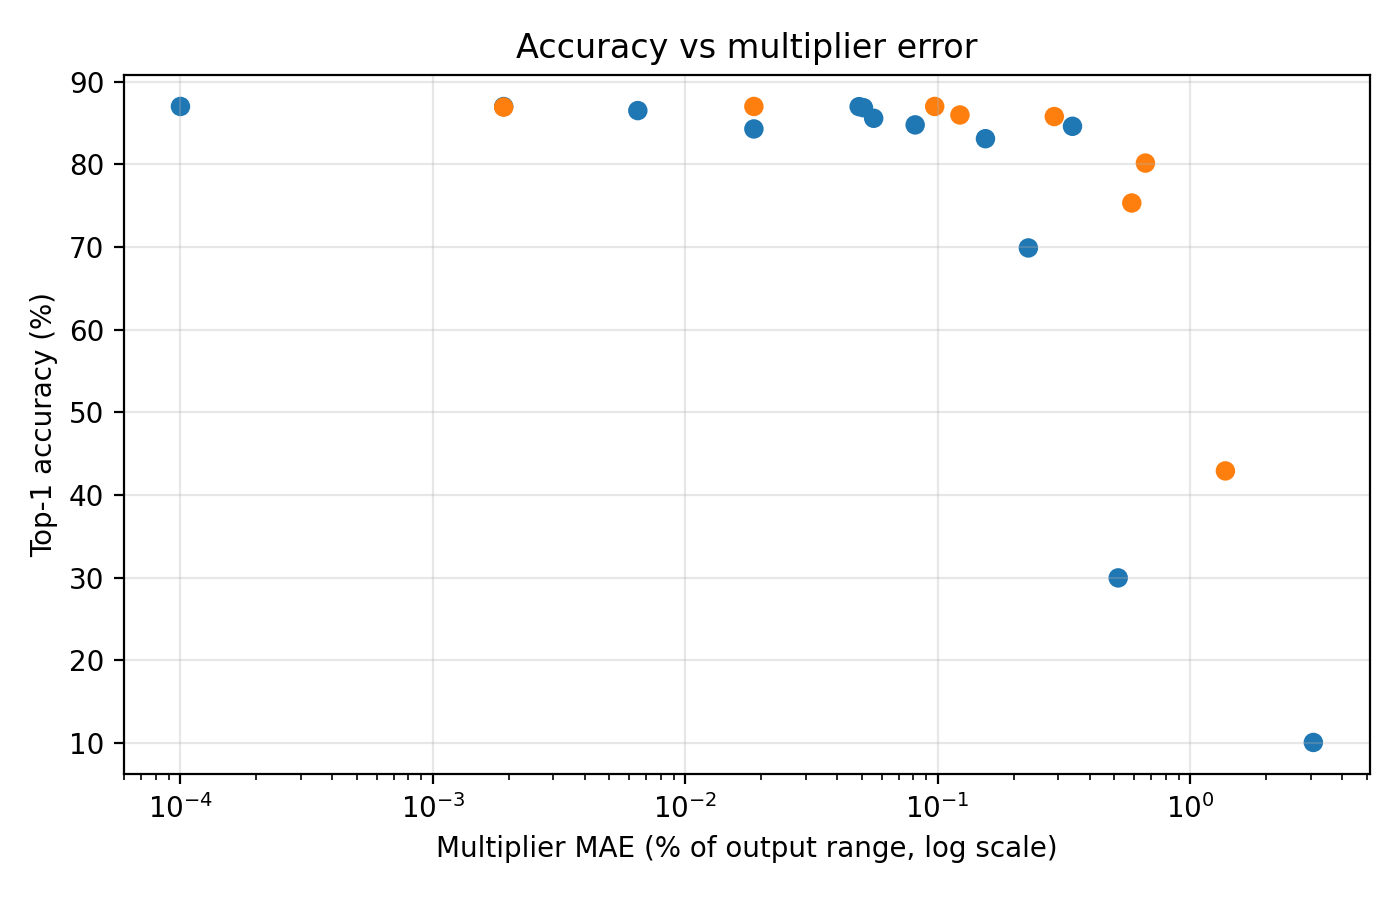

              name     acc  energy_saving_pct
17  own_truncOp_k1  0.8700          23.437500
15   own_dropPP_k6  0.8597          32.812500
18  own_truncOp_k2  0.8578          43.750000
2       mul8s_1KTY  0.8460          55.162162
19  own_truncOp_k3  0.8015          60.937500
9       mul8s_1L2D  0.6988          63.751987
20  own_truncOp_k4  0.4290          75.000000
8       mul8s_1L1G  0.2995          81.170111
0       mul8s_1KR3  0.1004          92.642289


In [ ]:
df = pd.read_csv(CSV)
am.make_plots(df, baseline_acc, out_dir=os.path.join(WORK, "plots"))
from IPython.display import Image, display
for f in ("pareto_acc_vs_energy.png", "acc_vs_mae.png"):
    display(Image(os.path.join(WORK, "plots", f)))
print(am.pareto_front(df[(df["swap"] == False) & (df["tag"].fillna("") == "")])[["name", "acc", "energy_saving_pct"]])

## 7. Operand order experiment
Approximate multipliers are generally not commutative. Here we swap which operand is the activation and which is the weight.

In [ ]:
lib_only = {k: v for k, v in registry.items() if v["family"] == "EvoApprox"}
df = am.run_sweep(qmodel, lib_only, xte, yte, N_EVAL, CSV, swap=True, baseline_acc=baseline_acc)
d = df[df["family"] == "EvoApprox"].pivot_table(index="name", columns="swap", values="acc")
d.columns = ["acc_act_first", "acc_weight_first"]
d["diff"] = d["acc_weight_first"] - d["acc_act_first"]
d.round(4)

,acc_act_first,acc_weight_first,diff
name,,,
mul8s_1KR3,0.1004,0.1000,-0.0004
mul8s_1KR6,0.8685,0.8377,-0.0308
mul8s_1KR8,0.8698,0.8464,-0.0234
mul8s_1KRC,0.8557,0.8057,-0.0500
mul8s_1KTY,0.8460,0.3008,-0.5452
mul8s_1KV8,0.8700,0.8700,0.0000
mul8s_1KVA,0.8699,0.8699,0.0000
mul8s_1KVB,0.8650,0.8650,0.0000
mul8s_1KVL,0.8310,0.4941,-0.3369


## 8. Per-layer sensitivity
Approximate one layer at a time (all others exact) for three library multipliers of increasing aggressiveness.

In [ ]:
names = [n for n in ("mul8s_1KR6", "mul8s_1KVL", "mul8s_1L2D") if n in registry]
rows = []
for n in names:
    accs = am.layer_sensitivity(qmodel, registry[n]["lut"], xte, yte, N_EVAL)
    rows.append(dict(multiplier=n, **{f"layer{i}": a for i, a in enumerate(accs)}))
sens = pd.DataFrame(rows).set_index("multiplier")
sens.to_csv(os.path.join(WORK, "layer_sensitivity.csv"))
print("exact int8 baseline:", round(baseline_acc, 4))
sens.round(4)

exact int8 baseline: 0.8696


,layer0,layer1,layer2,layer3,layer4
multiplier,,,,,
mul8s_1KR6,0.8700,0.8700,0.8673,0.8692,0.8701
mul8s_1KVL,0.8664,0.8485,0.8492,0.8650,0.8691
mul8s_1L2D,0.8275,0.8381,0.8345,0.8618,0.8687


## 9. Final numbers
Set `N_EVAL = 10000` in section 4, delete `sweep_results.csv`, and re-run sections 4 to 8 once the experiment design is settled.
All outputs (CSVs, plots, checkpoint) are in `WORK`.

In [ ]:
print("Outputs in", WORK)
!ls -la {WORK} {WORK}/plots

Outputs in /content/drive/MyDrive/approx_project
/content/drive/MyDrive/approx_project:
total 2463
drwx------ 4 root root    4096 Nov  2 03:10 .
drwx------ 7 root root    4096 Nov  2 01:52 ..
-rw------- 1 root root 2495793 Nov  2 02:21 cnn_bn.pt
drwx------ 2 root root    4096 Nov  2 02:30 .ipynb_checkpoints
-rw------- 1 root root     179 Nov  2 03:10 layer_sensitivity.csv
drwx------ 2 root root    4096 Nov  2 03:09 plots
-rw------- 1 root root    8412 Nov  2 02:37 sweep_results.csv

/content/drive/MyDrive/approx_project/plots:
total 173
drwx------ 2 root root   4096 Nov  2 03:09 .
drwx------ 4 root root   4096 Nov  2 03:10 ..
-rw------- 1 root root  58975 Nov  2 03:09 acc_vs_mae.png
-rw------- 1 root root 108570 Nov  2 03:09 pareto_acc_vs_energy.png
